In [1]:
import scipy.integrate as integrate
import scipy.optimize as sol
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy.stats import uniform
from numba import jit
import warnings
import pandas as pd

In [2]:
#@jit
def mnrm(x0,T,s0,V0,mu,n,k_tr,K):
    t_x=[0]
    x = [x0]
    i=0
    while t_x[i]<T:
        w_t = time_approx(t_x[i],x[-1],x[-1],np.random.uniform(0,1),s0,V0,mu,n,k_tr,K)
        x=np.append(x,[x[i]+1])
        t_x=np.append(t_x,[t_x[i]+w_t])
        i+=1
    return x[-1]

#@jit
def time_approx(s,xi,y_tot,eps,s0,V0,mu,n,k_tr,K):
    D=k_tr*xi
    V=V0*np.exp(mu*s)
    C=K*y_tot/(s0*6.022e2*n)
    a_prime = (mu*n*D*C/V)*(1+C/V)**(-n-1)
    a = D/(1+C/V)**n 
    return (-a+np.sqrt(a**2-2*a_prime*np.log(eps)))/a_prime

#@jit
def integrand(s,xi,T,s0,V0,mu,n,k_tr,K):
    V= V0*np.exp(s*mu)
    return (k_tr*xi)/(1+K*xi/(s0*n*6.022e2*V))**n 

#@jit
def func(w,tx,xi,Sj,Tj,T,s0,V0,mu,n,k_tr,K):
    return integrate.quad(integrand, tx, tx+w, args =(xi,T,s0,V0,mu,n,k_tr,K))[0] - (Sj-Tj)  

#@jit
def likelihood(x_fin,data,sigma):
    summ=0
    for i in range(len(x_fin)):  #BCD index
        summ+= norm.logpdf(x_fin[i], loc=data[i], scale=sigma)
    return summ

#@jit
def posterior_ratio(lik1,lik2,prior1,prior2,prop,sig_par,var,low,high):
    rate  = lik1-lik2 + prior1-prior2 + np.log(trunc_normal(prop,var,sig_par,low,high)+1e-300)-np.log(trunc_normal(var,prop,sig_par,low,high)+1e-300)
    return np.minimum(1,np.exp(rate))

#@jit
def trunc_normal(x,mean,sig,low,high):
    factor=norm.cdf((high-mean)/sig,0,1)-norm.cdf((low-mean)/sig,0,1)
    return norm.pdf((x-mean)/sig,0,1)/(sig*factor)

In [4]:
##################################################    
data = np.array([39, 41, 46, 51, 55])                       #average copy number per generation time
tau = np.array([100, 60, 40, 30, 24])                       #generation time
k_tr = np.array([2.23, 2.73, 2.84, 2.17, 1.49])             #RNA II transcription rate
K = np.array([7.27, 11.35, 14.5, 15.8, 15.2])/1.26          #RNA I parameter ratio: transcription rate over degradation rate
cell_vol = np.array([0.27,0.48,0.8,1.2,1.6])                #cell volume per generation time

In [20]:
warnings.filterwarnings('ignore')

L=50000             #length of chain 
n_init = 2.5        #initialization for n
s0_init = 0.03      #initialization for s0

n = np.zeros(L)
s0 = np.zeros([L])
n[0] = n_init
s0[0] = s0_init
V0 = cell_vol

epsilon = 1.0

for k in range(L-1):  
    ################ generate initial conditions #######################
    x0 = -1*np.ones(len(data))   
    d_t = np.zeros(len(data))
    
    for j in range(len(data)):
        d_t[j] = np.random.normal(tau[j],1)
        while x0[j]<0:
            x0[j] = np.floor(data[j]/2)+(np.random.poisson(1)-np.random.poisson(1))


    ################ sample n #######################
    x_fin1 = np.zeros(len(data))
    low_lim = 1
    high_lim = 10
    sig_param = 0.05
    prop = -1
    while prop<low_lim or prop>high_lim:
        prop = np.random.normal(n[k],sig_param) 
    for j in range(len(data)):
        x_fin1[j]= mnrm(x0[j],d_t[j],s0[k],V0[j],np.log(2)/d_t[j],prop,k_tr[j],K[j])
    #print(abs(x_fin1-data))
    lik1 = 1
    lik2 = 1       
    prior1 = uniform.pdf(prop,low_lim,high_lim)
    prior2 = uniform.pdf(n[k],low_lim,high_lim)
    if np.mean(abs(x_fin1-data))<epsilon: 
    #if max(abs(x_fin1-data))<epsilon: 
        rate=posterior_ratio(lik1,lik2,prior1,prior2,prop,sig_param,n[k],low_lim,high_lim)
        if np.random.uniform(0,1,1)<rate:    
           
            n[k+1]=prop
        else:
            n[k+1]=n[k]  
    else:
        n[k+1]=n[k]
        
    ################ sample s0 div time #######################   
    x_fin1 = np.zeros(len(data))
    x_fin2 = np.zeros(len(data))
    low_lim = 0
    high_lim = 1
    sig_param = 0.005
    prop = -1
    while prop<low_lim or prop>high_lim:
        prop = np.random.normal(s0[k],sig_param)
    for j in range(len(data)):
        x_fin1[j]= mnrm(x0[j],d_t[j],prop,V0[j],np.log(2)/d_t[j],n[k+1],k_tr[j],K[j])
    lik1 = 1
    lik2 = 1       
    prior1 = uniform.pdf(prop,low_lim,high_lim)
    prior2 = uniform.pdf(s0[k],low_lim,high_lim)
    rate=posterior_ratio(lik1,lik2,prior1,prior2,prop,sig_param,s0[k],low_lim,high_lim)
    if np.mean(abs(x_fin1-data))<epsilon:
    #if max(abs(x_fin1-data))<epsilon:   
        if np.random.uniform(0,1,1)<rate:    
            s0[k+1]=prop
        else:
            s0[k+1]=s0[k]
    else:
        s0[k+1]=s0[k]
        
    if k%100 == 0:
        print(k, 'n:',n[k+1],'s0:',s0[k+1])      
    #print(k, 'n:',n[k+1],'s0:',s0[k+1])
print("finished")

0 n: 2.5 s0: 0.03
100 n: 2.5 s0: 0.030857485793058154
200 n: 2.5 s0: 0.030857485793058154
300 n: 2.5 s0: 0.03349668578665628
400 n: 2.5 s0: 0.03349668578665628
500 n: 2.434268051508682 s0: 0.03349668578665628
600 n: 2.434268051508682 s0: 0.03349668578665628
700 n: 2.434268051508682 s0: 0.030916892975139658
800 n: 2.434268051508682 s0: 0.030916892975139658
900 n: 2.4620060767368988 s0: 0.030916892975139658
1000 n: 2.4620060767368988 s0: 0.030916892975139658
1100 n: 2.4620060767368988 s0: 0.030916892975139658
1200 n: 2.4620060767368988 s0: 0.030916892975139658
1300 n: 2.4620060767368988 s0: 0.030916892975139658
1400 n: 2.4514521647848095 s0: 0.030916892975139658
1500 n: 2.4514521647848095 s0: 0.030916892975139658
1600 n: 2.390556453623613 s0: 0.030916892975139658
1700 n: 2.390556453623613 s0: 0.030916892975139658
1800 n: 2.390556453623613 s0: 0.030916892975139658
1900 n: 2.390556453623613 s0: 0.031162129515343452
2000 n: 2.390556453623613 s0: 0.031162129515343452
2100 n: 2.39055645362361

16200 n: 2.6731415212775604 s0: 0.03249206354594193
16300 n: 2.6731415212775604 s0: 0.03249206354594193
16400 n: 2.6731415212775604 s0: 0.03249206354594193
16500 n: 2.6731415212775604 s0: 0.03249206354594193
16600 n: 2.6731415212775604 s0: 0.03249206354594193
16700 n: 2.6731415212775604 s0: 0.03249206354594193
16800 n: 2.6731415212775604 s0: 0.03249206354594193
16900 n: 2.6731415212775604 s0: 0.03249206354594193
17000 n: 2.6731415212775604 s0: 0.03249206354594193
17100 n: 2.6731415212775604 s0: 0.03249206354594193
17200 n: 2.613919908517798 s0: 0.03249206354594193
17300 n: 2.654513691372436 s0: 0.03249206354594193
17400 n: 2.654513691372436 s0: 0.03249206354594193
17500 n: 2.654513691372436 s0: 0.03249206354594193
17600 n: 2.654513691372436 s0: 0.03249206354594193
17700 n: 2.654513691372436 s0: 0.03249206354594193
17800 n: 2.654513691372436 s0: 0.03249206354594193
17900 n: 2.654513691372436 s0: 0.03249206354594193
18000 n: 2.617452818205733 s0: 0.03249206354594193
18100 n: 2.6174528182

32100 n: 2.9941621684656914 s0: 0.03863527537617862
32200 n: 3.0173087651692256 s0: 0.03863527537617862
32300 n: 3.0000985269097735 s0: 0.03863527537617862
32400 n: 2.994494256461452 s0: 0.03863527537617862
32500 n: 3.015525542896012 s0: 0.04026149331582322
32600 n: 2.984795671209905 s0: 0.04026149331582322
32700 n: 2.991309741091754 s0: 0.04026149331582322
32800 n: 2.991309741091754 s0: 0.0434937159237008
32900 n: 2.991309741091754 s0: 0.0434937159237008
33000 n: 2.991309741091754 s0: 0.0434937159237008
33100 n: 2.991309741091754 s0: 0.0434937159237008
33200 n: 2.991309741091754 s0: 0.0434937159237008
33300 n: 2.991309741091754 s0: 0.0434937159237008
33400 n: 2.991309741091754 s0: 0.0434937159237008
33500 n: 2.991309741091754 s0: 0.0434937159237008
33600 n: 3.0648915472943843 s0: 0.0434937159237008
33700 n: 3.0648915472943843 s0: 0.0434937159237008
33800 n: 3.0648915472943843 s0: 0.04101931764938624
33900 n: 3.0554979011675143 s0: 0.04101931764938624
34000 n: 3.0554979011675143 s0: 0.

48000 n: 2.4678275436455017 s0: 0.0292865683265645
48100 n: 2.4678275436455017 s0: 0.03293976458271949
48200 n: 2.4678275436455017 s0: 0.031858097788555924
48300 n: 2.4678275436455017 s0: 0.031858097788555924
48400 n: 2.4751251458753143 s0: 0.031858097788555924
48500 n: 2.4751251458753143 s0: 0.031858097788555924
48600 n: 2.4751251458753143 s0: 0.031858097788555924
48700 n: 2.4751251458753143 s0: 0.031858097788555924
48800 n: 2.4751251458753143 s0: 0.034717361345055875
48900 n: 2.4751251458753143 s0: 0.034717361345055875
49000 n: 2.4751251458753143 s0: 0.034717361345055875
49100 n: 2.4751251458753143 s0: 0.03236599940397997
49200 n: 2.4751251458753143 s0: 0.03236599940397997
49300 n: 2.4751251458753143 s0: 0.03236599940397997
49400 n: 2.4751251458753143 s0: 0.03236599940397997
49500 n: 2.3886020230663383 s0: 0.03236599940397997
49600 n: 2.3886020230663383 s0: 0.03236599940397997
49700 n: 2.3886020230663383 s0: 0.03236599940397997
49800 n: 2.3886020230663383 s0: 0.03236599940397997
4990

In [22]:
np.savetxt('n4.csv', n, delimiter=",",header=" ")
np.savetxt('s04.csv', s0, delimiter=",",header=" ")       

In [26]:
n=[]
s0=[]
for i in range(4):
    data_n = pd.read_csv(f'n{i+1}.csv',skiprows=1).values
    data_s = pd.read_csv(f's0{i+1}.csv',skiprows=1).values
    n = np.append(n,data_n)
    s0 = np.append(s0,data_s)

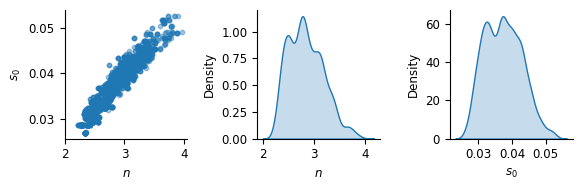

In [49]:
f, ax = plt.subplots(1, 3, figsize=(6, 2))
fontsiz = 8.5

ax[0].scatter(n[::100], s0[::100], s=10,alpha=0.4)

sns.kdeplot(n[::100], ax=ax[1], shade=True)
sns.kdeplot(s0[::100], ax=ax[2], shade=True)

ax[0].set_xlabel(r'$n$', fontsize=fontsiz)
ax[0].set_ylabel(r'$s_0$', fontsize=fontsiz)
ax[0].set_xticks([2,3,4])
ax[1].set_xlabel(r'$n$', fontsize=fontsiz)
ax[2].set_xlabel(r'$s_0$', fontsize=fontsiz)
# set tick label sizes
for a in ax:
    a.tick_params(axis='both', labelsize=fontsiz)
ax[1].set_ylabel('Density',fontsize=fontsiz)
ax[2].set_ylabel('Density',fontsize=fontsiz)

sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
np.savetxt('n_s0_fin_new.csv',np.array([[n, s0]]),delimiter=',',header='n,s0',comments='')